# GeoReady 03 · Grid headroom, supply curves and readiness

Each zone sits behind three nested NTCSA GCCA 2025 limits: its **substation**, its **local area**
and its **supply area**. Limits are shared, so capacity is allocated cheapest-first and the
same MW are never counted twice (tests/test_allocate.py checks this against a linear programme).
Unknown headroom is not treated as available.

Three scenarios:

| scenario | limits applied |
|---|---|
| GCCA 2025 as published | substation, local area and supply area |
| Upstream strengthened | substation only, as if the backbone were reinforced |
| Technical potential | none |

Limits are shared with projects outside the province, which are not modelled, so every
allocation here is an upper bound.

In [1]:
import os, sys
from pathlib import Path
def _root():  # the geoready folder: from GEOREADY_ROOT, the working folder, or the QGIS Notebook plugin
    if os.environ.get("GEOREADY_ROOT"):
        return Path(os.environ["GEOREADY_ROOT"])
    starts = [Path.cwd()]
    try:
        from qgis.PyQt.QtCore import QSettings
        starts.append(Path(QSettings().value("QGISNotebook/last_directory", "") or "."))
    except ImportError:
        pass
    return next((p for s in starts for p in [s, *s.parents] if (p / "src" / "geoready").exists()), None)
ROOT = _root()
assert ROOT, "Open this notebook from inside the geoready folder, or set GEOREADY_ROOT"
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
if "qgis" in sys.modules:          # inside QGIS: draw figures off-screen
    import matplotlib; matplotlib.use("Agg")
from geoready.nb import show
CONFIG = "config/northern_cape_pv.yaml"

In [2]:
import pandas as pd
from geoready.run import Run
from geoready import grid, allocate as al, readiness, plots
run = Run(CONFIG); cfg = run.cfg
z = pd.read_csv(run.path("zones_stage2.csv"))
z = grid.attach_limits(z, grid.read_gcca(cfg["vectors"]))
scen = cfg["grid"]["scenarios"]
res = grid.run_scenarios(z, scen, unknown=cfg["grid"]["unknown_policy"])
show(pd.DataFrame({sid: {"connectable MW": round(a["alloc_mw"].sum()),
                    "zones with MW": int((a["alloc_mw"] > 0).sum()),
                    "zones behind unknown limits": int((a["grid_status"] == "unknown").sum())}
              for sid, a in res.items()}).T)

,connectable MW,zones with MW,zones behind unknown limits
published,0,0,0
strengthened,4290,18,0
unconstrained,1563685,2132,0


What stops each zone under the published limits:

In [3]:
show(res["published"]["binding"].value_counts().head(12))

binding
supply:Northern Cape                 445
local:Hydra Central/Hydra Central    395
local:Northern Cape/Namaqualand      352
sub:Kronos                           236
sub:Boundary                         215
sub:Paulputs                         143
sub:Garona                           138
sub:Helios                            99
sub:Lewensaar                         50
sub:Koruson                           30
sub:Upington                          29
Name: count, dtype: int64

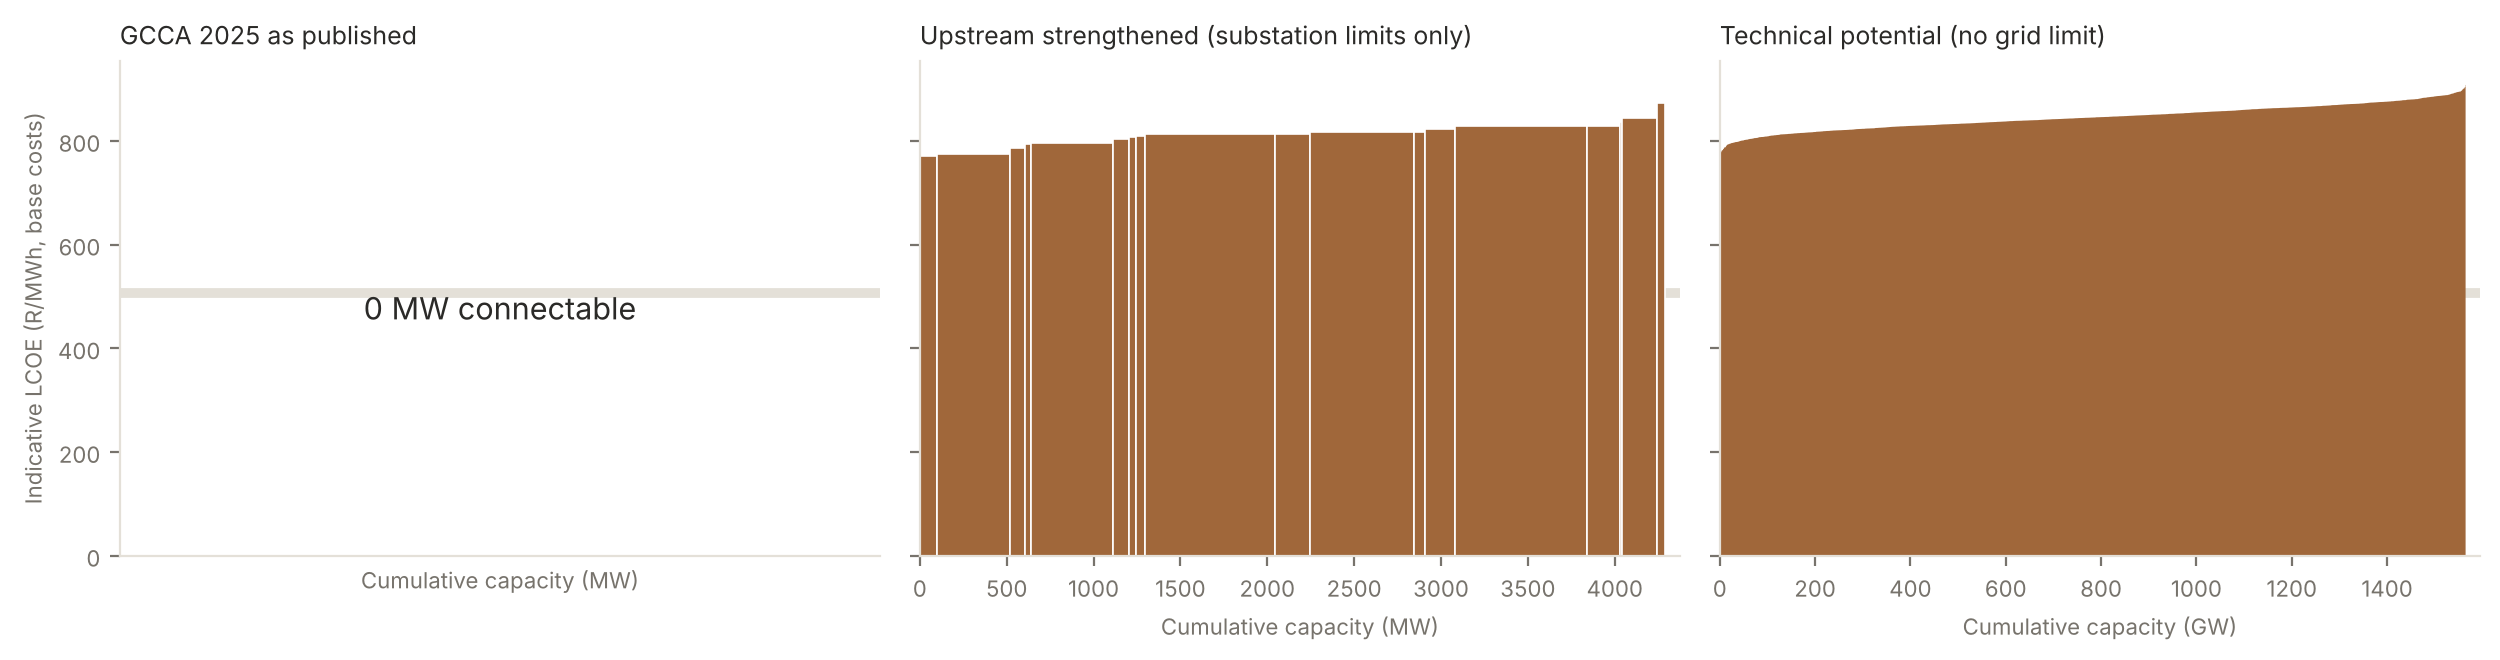

In [4]:
curves = {sid: al.supply_curve(a, cost_col="lcoe_base") for sid, a in res.items()}
fig = plots.supply_curves(curves, cfg["economics"]["reference_bids_r_per_mwh"],
                          {k: v["label"] for k, v in scen.items()})
fig.savefig(run.path("supply_curves.png"), dpi=160, bbox_inches="tight")
show(fig, save_as=run.path("supply_curves.png"))

### Readiness

A weighted sum of five criteria, each normalised to 0–1 with **fixed bounds** from the config,
so a score means the same in every scenario. Grid headroom is the share of a zone's technical
capacity that the scenario lets it connect; under the published GCCA it is zero everywhere.

In [5]:
crit = cfg["readiness"]
scored = {sid: readiness.score(a, crit) for sid, a in res.items()}
show(pd.DataFrame({sid: s["readiness"].describe()[["min", "50%", "max"]] for sid, s in scored.items()}).T.round(3))

,min,50%,max
published,0.104,0.279,0.575
strengthened,0.104,0.279,0.711
unconstrained,0.354,0.529,0.825


### Sensitivity: does the top of the list survive other weights?

In [6]:
import numpy as np
base = scored["strengthened"].set_index("zone_id")["readiness"]
top = set(base.nlargest(50).index)
alts = {"resource-led": dict(resource=.4, cost=.2, grid_access=.1, grid_headroom=.2, permitting=.1),
        "grid-led": dict(resource=.1, cost=.2, grid_access=.25, grid_headroom=.35, permitting=.1),
        "permitting-led": dict(resource=.15, cost=.2, grid_access=.1, grid_headroom=.2, permitting=.35)}
rows = {}
for name, w in alts.items():
    c2 = {k: dict(v, weight=w[k]) for k, v in crit.items()}
    s2 = readiness.score(res["strengthened"], c2).set_index("zone_id")["readiness"]
    rows[name] = {"top-50 overlap": len(top & set(s2.nlargest(50).index)) / 50,
                  "Spearman rho": round(base.rank().corr(s2.rank()), 3)}
sens = pd.DataFrame(rows).T
sens.to_csv(run.path("sensitivity.csv"))
show(sens)

,top-50 overlap,Spearman rho
resource-led,0.28,0.880
grid-led,0.92,0.913
permitting-led,0.86,0.995


In [7]:
out = z.copy()
for sid, s in scored.items():
    out[f"alloc_mw_{sid}"] = s["alloc_mw"].values
    out[f"binding_{sid}"] = s["binding"].values
    out[f"readiness_{sid}"] = s["readiness"].values
    out[f"headroom_share_{sid}"] = s["headroom_share"].values
for n in crit:
    out[f"n_{n}"] = scored["strengthened"][f"n_{n}"].values   # criteria shown for the strengthened case
out.to_csv(run.path("zones_stage3.csv"), index=False)
for sid, c in curves.items():
    c.to_csv(run.path(f"supply_curve_{sid}.csv"), index=False)